# 01. KRX 가격 보정 확인 (분할 · 배당 · 유상증자 · 기준가)

- **목표**: KRX 원주가를 "회계상 사건이 없었던 것처럼" 이어 붙인 최종 가격표 `data/krx_adjusted.parquet` 가 맞게 만들어졌는지 숫자와 그림으로 확인한다.
- 이 노트북은 파일을 **읽기만** 한다. 파일은 아래 터미널 명령으로 만든다.
  (예전 01·02번 노트북은 노트북 안에서 파일을 저장했다. 그러면 같은 파일을 다른 방식으로 덮어쓸 위험이 있어서 저장 칸을 모두 없앴다.)
- 예전 노트북 01(분할 찾기)·02(분할 보정)·03(배당)·04(남은 큰 변동)·06(유상증자)·08의 5절(기준가 보정)을 이 한 권으로 합쳤다.

## 파일을 만드는 순서 (터미널에서, 프로젝트 폴더 기준)

| 순서 | 명령 | 만드는 파일 | 키 |
|---|---|---|---|
| 0 | `python -m indexbeater.krx_source collect` | krx_raw_daily.parquet (원주가) | KRX 키 필요 |
| 1 | `python -m indexbeater.krx_source splits` | krx_split_events.csv, krx_split_review.csv | 필요 없음 |
| 2 | `python -m indexbeater.krx_source adjust --split-only` | krx_adjusted_split_only.parquet | 필요 없음 |
| 3 | `python -m indexbeater.krx_source jumps` | krx_jump_review.csv | 필요 없음 |
| 4 | `python -m indexbeater.krx_source yahoo_divs` | yahoo_dividends_2011_2014.csv | 필요 없음 |
| 5 | `python -m indexbeater.krx_source dividends` | krx_dividend_events.csv, krx_dividend_review.csv | OpenDART 키 필요 |
| 6 | `python -m indexbeater.krx_source rights --build` | krx_rights_events.csv (이미 받아 둔 공시로 만든다) | 필요 없음 |
| 7 | `python -m indexbeater.krx_source adjust` | krx_adjusted.parquet, krx_base_events.csv | 필요 없음 |

- 키는 환경변수로만 넣는다. 코드·문서·노트북에 키를 적지 않는다.
- 7번에 `--exclude-low` 를 붙이면 날짜가 불확실한 2023 사업연도 이후 배당(low)을 빼고 만든다.

## 보정 계수 4가지 (모두 "그날 **이전** 가격"에 곱한다)

| 열 | 무엇 | 근거 |
|---|---|---|
| `split_factor` | 분할·무상증자·병합 | 상장주식수 변화 + 가격 변화가 같은 비율 |
| `div_factor` | 배당 | DART 배당(2015~) + 야후 배당(2011~2014) |
| `rights_factor` | 주주배정 유상증자 | DART 공시 + 신주 상장 확인 (confirmed 만) |
| `base_factor` | 그 밖에 거래소가 기준가를 바꾼 날 | KRX 기준가 ÷ 전일종가 |

- `close_s` = 분할만 보정한 종가 (네이버·새 야후 `Close` 와 같은 종류)
- `adj_close` = 위 4가지를 모두 곱한 종가 (신호·백테스트에 쓰는 값)

In [1]:
# 이 칸을 맨 먼저 실행한다.
# 노트북이 어느 폴더에서 열려도, indexbeater 폴더가 있는 프로젝트 폴더를 찾아서 길 목록(sys.path)에 넣는다.
# (예전 07~09번 노트북은 이 칸이 없어서 "indexbeater 를 찾을 수 없다"는 오류가 났다.)
import os, sys
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "indexbeater")) and os.path.dirname(root) != root:
    root = os.path.dirname(root)          # 못 찾으면 한 칸 위 폴더로 올라가서 다시 찾는다
sys.path.insert(0, root)
print("프로젝트 폴더:", root)

프로젝트 폴더: C:\Users\gram\Desktop\project\buysignal


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from indexbeater.krx_source import paths, external

# 그래프의 한글이 네모(□)로 깨지지 않게 윈도우 기본 한글 글꼴을 쓴다.
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False      # 마이너스(-) 기호가 깨지는 것도 막는다
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")   # 표의 소수점은 네 자리까지만

# 최종 표에서 이 노트북에 필요한 열만 읽는다 (약 1,000만 줄이라 열을 줄여야 빠르다).
cols = ["date", "market", "code", "name", "close", "close_s", "adj_close", "listed_shares",
        "split_factor", "div_factor", "rights_factor", "base_factor"]
adj = pd.read_parquet(paths.ADJUSTED, columns=cols).sort_values(["code", "date"]).reset_index(drop=True)
print("최종 표:", f"{len(adj):,}", "줄,", f"{adj['code'].nunique():,}", "종목,", adj["date"].min().date(), "~", adj["date"].max().date())
print(adj["market"].value_counts().to_string())

최종 표: 10,173,209 줄, 4,982 종목, 2011-11-17 ~ 2026-11-17
market
KOSDAQ    5056241
KOSPI     3392955
ETF       1724013


## 1. 분할·무상증자 찾기 결과

- **왜**: 삼성전자는 2018-05-04에 1주를 50주로 쪼갰다. 가격이 265만 원 → 5만 원대로 보이지만 회사 가치는 그대로다. 그대로 두면 수익률이 -98%로 잡힌다.
- **찾는 방법** (`splits.py`)
  1. 상장주식수가 하루 만에 1.3배 이상 늘거나 1/1.3 이하로 줄어든 날을 후보로 뽑는다.
  2. 그 근처에서 가격도 같은 비율로 움직였는지 본다. 가까운 곳(앞 10일~뒤 3일)은 15% 오차까지, 먼 곳(앞 60일까지)은 3% 오차까지만 인정한다.
  3. 가격이 안 맞으면 자동으로 고치지 않고 확인 목록(`krx_split_review.csv`)으로 뺀다. (대표 예: 유상증자)
- 코스피·코스닥 개별 종목만 본다. ETF는 주식 수(상장좌수)가 설정·환매로 수시로 바뀌어 분할과 구분되지 않는다.
- `kind`: `split` = 주식 수 증가(분할·무상증자), `reverse_split` = 감소(병합·감자). `evidence`: `close` = 종가 비율로 확인, `base` = KRX 기준가 비율로 확인.

In [3]:
from indexbeater.krx_source.splits import PRICE_TOL, SHARE_JUMP, WIN_AFTER, WIN_BEFORE

splits = pd.read_csv(paths.SPLIT_EVENTS, dtype={"code": str}, parse_dates=["ex_date", "share_change_date"])
split_review = pd.read_csv(paths.SPLIT_REVIEW, dtype={"code": str})
print("기준값: 주식 수", SHARE_JUMP, "배 / 가격 오차", PRICE_TOL, "/ 찾는 범위 앞", WIN_BEFORE, "~ 뒤", WIN_AFTER, "거래일")
print("분할 확정:", len(splits), "건,", splits["code"].nunique(), "종목 / 사람이 확인할 것:", len(split_review), "건")
print()
print("종류별 건수"); print(splits["kind"].value_counts().to_string())
print("확인에 쓴 가격"); print(splits["evidence"].value_counts().to_string())
print("price_dev 요약 (주식 수 비율과 가격 비율의 차이. 0에 가까울수록 정확)")
print(splits["price_dev"].describe().to_string())
# 주식 수가 가장 많이 늘어난 것부터 10건. 삼성전자(50배) 같은 유명한 분할이 보이면 잘 잡고 있는 것이다.
splits.sort_values("share_ratio", ascending=False).head(10)[["code", "name", "ex_date", "share_ratio", "kind", "evidence", "price_dev"]]

기준값: 주식 수 1.3 배 / 가격 오차 0.15 / 찾는 범위 앞 10 ~ 뒤 3 거래일
분할 확정: 1840 건, 1255 종목 / 사람이 확인할 것: 1611 건

종류별 건수
kind
split            1101
reverse_split     739
확인에 쓴 가격
evidence
base     1485
close     355
price_dev 요약 (주식 수 비율과 가격 비율의 차이. 0에 가까울수록 정확)
count   1,840.0000
mean        0.0121
std         0.0298
min         0.0000
25%         0.0000
50%         0.0002
75%         0.0017
max         0.1499


,code,name,ex_date,share_ratio,kind,evidence,price_dev
855,079650,서산,2017-01-19,50.0000,split,base,0.0012
170,005935,삼성전자우,2018-05-04,50.0000,split,base,0.0000
169,005930,삼성전자,2018-05-04,50.0000,split,base,0.0000
138,004415,서울식품우,2017-10-25,25.0000,split,base,0.0000
136,004410,서울식품,2017-10-25,25.0000,split,base,0.0022
1614,290690,아리바이오홀딩스,2023-12-26,15.0000,split,base,0.0002
21,000670,영풍,2025-04-25,10.3735,split,base,0.0360
14,000420,로케트전기,2013-03-25,10.2986,split,base,0.0290
160,005690,파미셀,2011-12-19,10.0287,split,base,0.0029
44,001340,PKC,2012-05-10,10.0000,split,base,0.0000


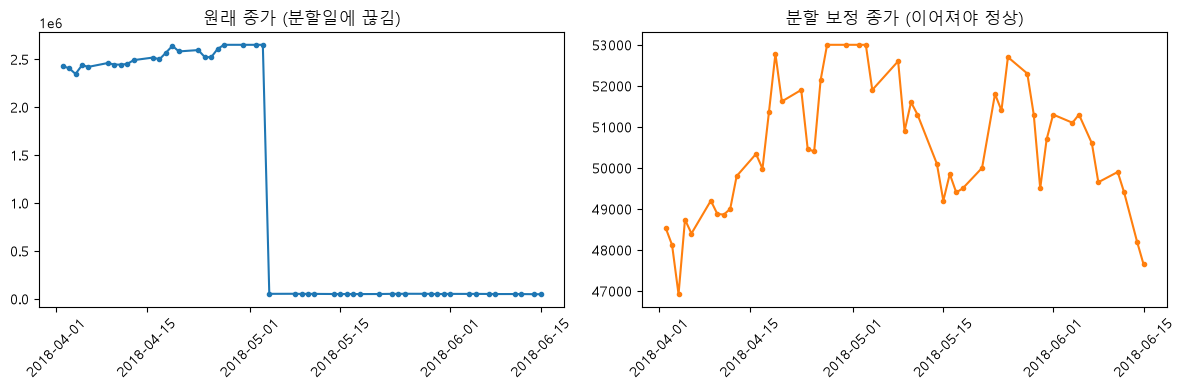

,date,close,close_s,split_factor,listed_shares
1277515,2018-04-30,"2,650,000.0000","53,000.0000",0.0200,"128,386,494.0000"
1277516,2018-05-02,"2,650,000.0000","53,000.0000",0.0200,"128,386,494.0000"
1277517,2018-05-03,"2,650,000.0000","53,000.0000",0.0200,"128,386,494.0000"
1277518,2018-05-04,"51,900.0000","51,900.0000",1.0000,"6,419,324,700.0000"
1277519,2018-05-08,"52,600.0000","52,600.0000",1.0000,"6,419,324,700.0000"
1277520,2018-05-09,"50,900.0000","50,900.0000",1.0000,"6,419,324,700.0000"
1277521,2018-05-10,"51,600.0000","51,600.0000",1.0000,"6,419,324,700.0000"


In [4]:
# 삼성전자로 직접 확인: 원래 종가는 분할일에 절벽처럼 떨어지고, 분할 보정 종가(close_s)는 이어져야 한다.
sam = adj[adj["code"] == "005930"]
view = sam[(sam["date"] >= "2018-04-01") & (sam["date"] <= "2018-06-15")]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(view["date"], view["close"], marker="o", ms=3); ax[0].set_title("원래 종가 (분할일에 끊김)")
ax[1].plot(view["date"], view["close_s"], marker="o", ms=3, color="tab:orange"); ax[1].set_title("분할 보정 종가 (이어져야 정상)")
for a in ax:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
ex = splits.loc[splits["code"] == "005930", "ex_date"].iloc[0]
# 분할일 앞뒤 며칠을 숫자로 본다. 분할일 이전 줄은 split_factor 가 0.02(=1/50), 이후는 1 이다.
sam[(sam["date"] >= ex - pd.Timedelta(days=6)) & (sam["date"] <= ex + pd.Timedelta(days=6))][["date", "close", "close_s", "split_factor", "listed_shares"]]

In [5]:
# 확인 목록: 주식 수는 크게 바뀌었는데 가격이 같은 비율로 안 움직인 것. 틀린 것이 아니라 "판단 보류"다.
print("주식 수 변화 비율 요약"); print(split_review["share_ratio"].describe().to_string())
split_review.sort_values("share_ratio", ascending=False).head(10)

주식 수 변화 비율 요약
count   1,611.0000
mean        2.2083
std         2.8683
min         0.0007
25%         1.3567
50%         1.5111
75%         1.9336
max        45.6263


,code,name,share_change_date,share_ratio,reason,best_price_dev
1301,206640,바디텍메드,2015-09-11,45.6263,shares_jump_without_matching_price_move,0.9687
827,064520,테크엘,2020-01-13,38.5855,shares_jump_without_matching_price_move,0.5524
1547,365590,하이딥,2022-05-12,27.7726,shares_jump_without_matching_price_move,0.9491
282,009410,태영건설,2024-07-22,24.8796,shares_jump_without_matching_price_move,0.9598
358,012650,쌍용건설,2013-07-31,24.5366,shares_jump_without_matching_price_move,0.9592
61,001440,대한전선,2015-10-21,24.1331,shares_jump_without_matching_price_move,0.9586
1543,363260,모비데이즈,2022-06-08,23.3229,shares_jump_without_matching_price_move,0.9477
225,006380,카프로,2024-05-24,21.1250,shares_jump_without_matching_price_move,0.9527
1449,284620,카이노스메드,2020-06-08,18.9702,shares_jump_without_matching_price_move,0.9376
1338,217270,넵튠,2016-12-14,17.2138,shares_jump_without_matching_price_move,0.9391


## 2. 분할 보정이 맞게 되었나

- 보정이 맞다면 **분할일의 하루 수익률(보정 후)** 은 상식적인 크기(대부분 ±30% 안)여야 한다. 보정 전은 분할 비율만큼 크게 끊겨 있다.
- 또 하나: "못 찾은 분할이 남았나"를 보려고, 전체 종목에서 하루 ±31%를 넘는 날을 보정 전·후로 센다. (한국 주식은 2015-06-15부터 하루 ±30%까지만 움직인다. 그 전은 ±15%.)
- `shift(1)` 은 한 줄 위(전날) 값을 가져오는 명령이다. 종목별로 따로 해야 해서 `groupby("code")` 를 쓴다.

In [6]:
stock = adj[adj["market"].isin(["KOSPI", "KOSDAQ"])].copy()
g = stock.groupby("code", sort=False)
stock["ret_raw"] = stock["close"] / g["close"].shift(1) - 1        # 원래 종가의 하루 수익률
stock["ret_s"] = stock["close_s"] / g["close_s"].shift(1) - 1      # 분할 보정 종가의 하루 수익률
print("split_factor 가 1이 아닌 종목 수:", stock.loc[stock["split_factor"] != 1, "code"].nunique(), "/ 분할 목록 종목 수:", splits["code"].nunique())

# 분할일 줄만 뽑아 보정 전·후 수익률을 나란히 놓는다
key = splits[["code", "name", "ex_date", "share_ratio", "kind"]].rename(columns={"ex_date": "date"})
chk = key.merge(stock[["code", "date", "ret_raw", "ret_s"]], on=["code", "date"], how="left")
print("분할일 줄을 못 찾은 건:", int(chk["ret_s"].isna().sum()))
print(pd.DataFrame({"보정 전": chk["ret_raw"].describe(), "보정 후": chk["ret_s"].describe()}).to_string())
print("보정 후에도 분할일 하루 변동이 30%를 넘는 건:", int((chk["ret_s"].abs() > 0.30).sum()))

LIMIT = 0.31   # 하루 상하한 30% + 여유 1%p
print()
print("하루 31% 초과 (코스피·코스닥): 보정 전", f"{(stock['ret_raw'].abs() > LIMIT).sum():,}", "건 → 분할 보정 후", f"{(stock['ret_s'].abs() > LIMIT).sum():,}", "건")

split_factor 가 1이 아닌 종목 수: 1255 / 분할 목록 종목 수: 1255


분할일 줄을 못 찾은 건: 0
            보정 전       보정 후
count 1,840.0000 1,840.0000
mean      1.8338     0.0207
std       4.5676     0.1260
min      -0.9807    -0.3103
25%      -0.5251    -0.0500
50%      -0.3181     0.0000
75%       3.4935     0.0710
max      49.0183     0.5147
보정 후에도 분할일 하루 변동이 30%를 넘는 건: 73

하루 31% 초과 (코스피·코스닥): 보정 전 3,139 건 → 분할 보정 후 1,502 건


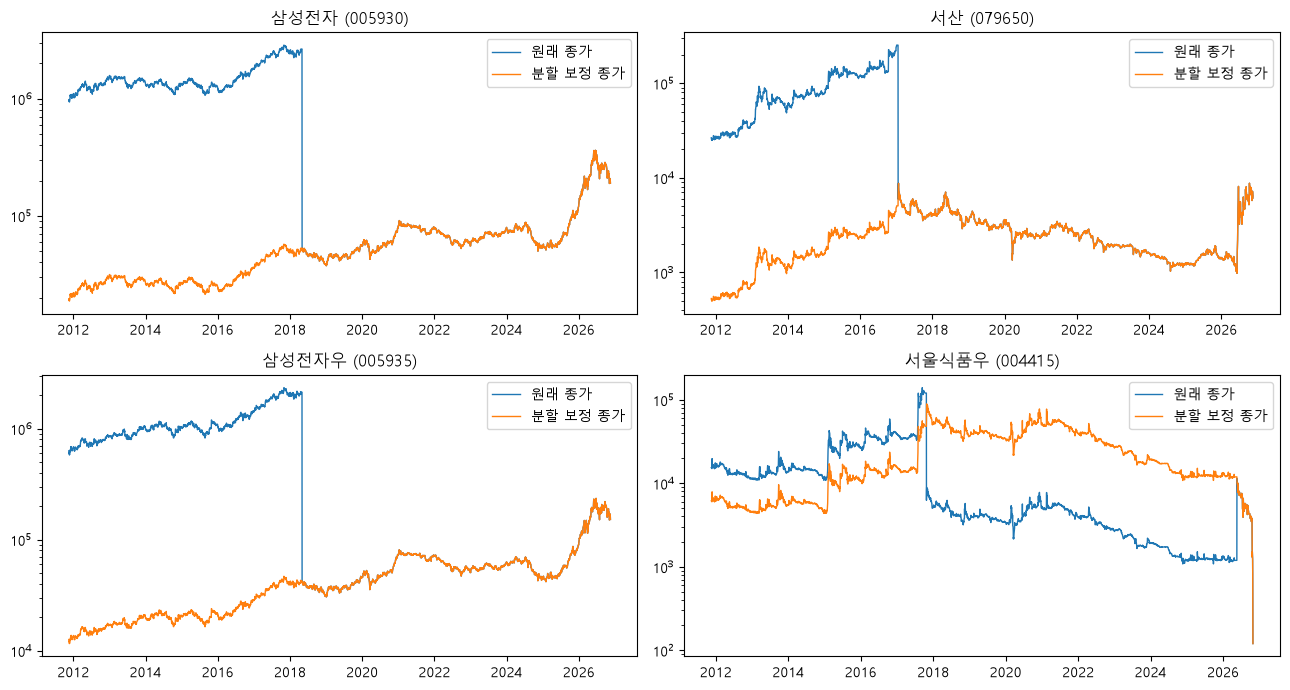

In [7]:
# 분할 배율이 큰 종목 3개 + 삼성전자. 세로축은 로그 눈금(한 칸 = 몇 배)이다.
top = splits.sort_values("share_ratio", ascending=False).drop_duplicates("code")["code"].tolist()
codes = (["005930"] + [c for c in top if c != "005930"])[:4]
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, c in zip(axes.ravel(), codes):
    one = stock[stock["code"] == c]
    ax.plot(one["date"], one["close"], label="원래 종가", lw=1)
    ax.plot(one["date"], one["close_s"], label="분할 보정 종가", lw=1)
    ax.set_yscale("log"); ax.set_title(f"{one['name'].iloc[-1]} ({c})"); ax.legend()
plt.tight_layout(); plt.show()

**읽는 법**
- 주황 선(분할 보정)은 처음부터 끝까지 한 줄로 이어지고, 파란 선(원래 종가)은 분할일에 뚝 떨어지면 정상이다.
- 분할일 1,840건 중 보정 후에도 하루 30%를 넘게 움직인 날이 70건 남짓 있다. 3절 끝에서 나눠 보면 대부분은 등락이 30~31% 사이, 즉 하루 가격제한폭 안의 **실제 상한가·하한가**다. 나머지 10여 건은 3절의 D·E(주식 수 변화가 겹친 의심)라 확인 목록에 들어 있다.

## 3. 분할 보정 후에도 남은 하루 큰 변동 — 종류 나누기

- `jumps` 명령이 분할 보정 후에도 하루 ±31%를 넘은 날을 모아 `krx_jump_review.csv` 에 넣었다.
- 하나씩 사람이 볼 수 없어서 **네이버를 두 번째 눈**으로 써서 종류를 나눴다.

| 종류 | 뜻 | 처리 |
|---|---|---|
| A | 가격이 1원 이하 (임시 값) | 표시만 |
| B | 거래정지 후 재개, 네이버도 같은 변동 | 진짜 움직임 → 그대로 |
| C | 거래정지 아님, 네이버도 같은 변동 | 진짜 움직임 → 그대로 |
| D | 거래정지 후 재개, 네이버는 다른 값 | 정지 중 주식 수 변화 의심 → 확인 목록 |
| E | 거래정지 아님, 네이버는 다른 값 | 우리가 놓친 주식 수 변화 의심 → 확인 목록 |

분할 보정 후에도 하루 31%를 넘은 날: 1,520 건, 635 종목
kind
A_1원              6
B_정지후_네이버일치     356
C_실제변동_네이버일치    741
D_정지후_네이버만보정    372
E_네이버만보정         45


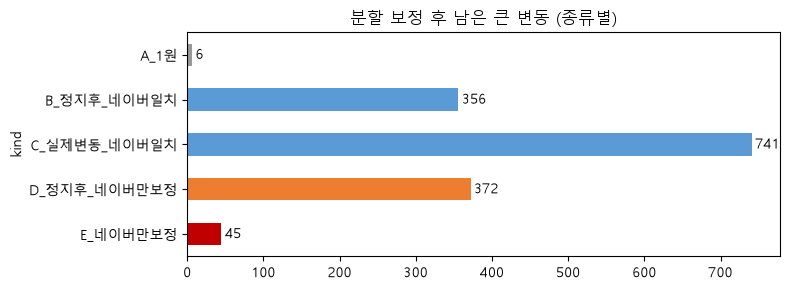

두 자료 차이 비율(implied)에서 자주 나온 값
implied
2.0000     37
0.5000     27
5.0000      9
1.5000      8
0.6200      7
3.0000      7
10.0000     6
1.1700      6

분할일 30% 초과 73 건의 종류: {nan: 55, 'D_정지후_네이버만보정': 13, 'E_네이버만보정': 4, 'B_정지후_네이버일치': 1}
  그중 목록에 없고 등락이 30~31% 사이인 것: 55


In [8]:
jumps = pd.read_csv(paths.JUMP_REVIEW, dtype={"code": str}, parse_dates=["date", "prev_date"])
print("분할 보정 후에도 하루 31%를 넘은 날:", f"{len(jumps):,}", "건,", jumps["code"].nunique(), "종목")
order = ["A_1원", "B_정지후_네이버일치", "C_실제변동_네이버일치", "D_정지후_네이버만보정", "E_네이버만보정"]
cnt = jumps["kind"].value_counts().reindex(order).fillna(0).astype(int)
print(cnt.to_string())
ax = cnt.plot(kind="barh", figsize=(8, 3), color=["#999999", "#5b9bd5", "#5b9bd5", "#ed7d31", "#c00000"])
ax.invert_yaxis(); ax.set_title("분할 보정 후 남은 큰 변동 (종류별)")
for i, v in enumerate(cnt.values):
    ax.text(v + 5, i, str(v), va="center")
plt.tight_layout(); plt.show()

# D·E 에서 (1+KRX 수익률)/(1+네이버 수익률) 이 0.5, 0.33, 2 처럼 딱 떨어지면 주식 수 변화(무상증자·감자)의 흔적이다.
de = jumps[jumps["kind"].str[0].isin(["D", "E"])].copy()
de["implied"] = (1 + de["ret"]) / (1 + de["naver_ret"])
print("두 자료 차이 비율(implied)에서 자주 나온 값"); print(de["implied"].round(2).value_counts().head(8).to_string())

# 2절의 '분할일인데도 하루 30% 넘게 움직인 날'이 이 목록에서 어떤 종류인지 본다. (NaN = 이 목록에 없음)
bs = chk.loc[chk["ret_s"].abs() > 0.30, ["code", "date", "ret_s"]].merge(jumps[["code", "date", "kind"]], on=["code", "date"], how="left")
print()
print("분할일 30% 초과", len(bs), "건의 종류:", bs["kind"].value_counts(dropna=False).to_dict())
print("  그중 목록에 없고 등락이 30~31% 사이인 것:", int((bs["kind"].isna() & (bs["ret_s"].abs() <= LIMIT)).sum()))

**읽는 법**
- 파란색(B, C)은 두 자료가 같은 값을 보여 주는 **진짜 시장 움직임**이다. 고치면 오히려 틀린다.
- 빨간색(E)은 처음 643건이었다. 원인은 "무상증자는 가격이 먼저 바뀌고 새 주식은 몇 주 뒤 상장된다"는 점이었다. 찾는 범위를 앞 60거래일로 넓히되 먼 곳은 가격 오차 3% 이내만 인정하도록 고쳐 45건 안팎으로 줄였다.
- 이 규칙은 네이버로 따로 검산했다: 먼 곳에서 찾은 후보 중 가격 오차 0~3% 는 거의 전부 네이버와 일치, 3~15% 는 거의 0% 일치. 그래서 "넓게 찾되 먼 곳은 엄격하게"가 맞았다.
  (이 검산은 전 종목 분할 찾기를 한 번 더 돌려야 해서 무거우므로, 이 노트북에서는 결과만 적는다.)
- 주황(D)은 자동으로 고치지 않고 확인 목록에 둔다. 틀리게 고치는 것보다 표시만 하는 것이 안전하다.

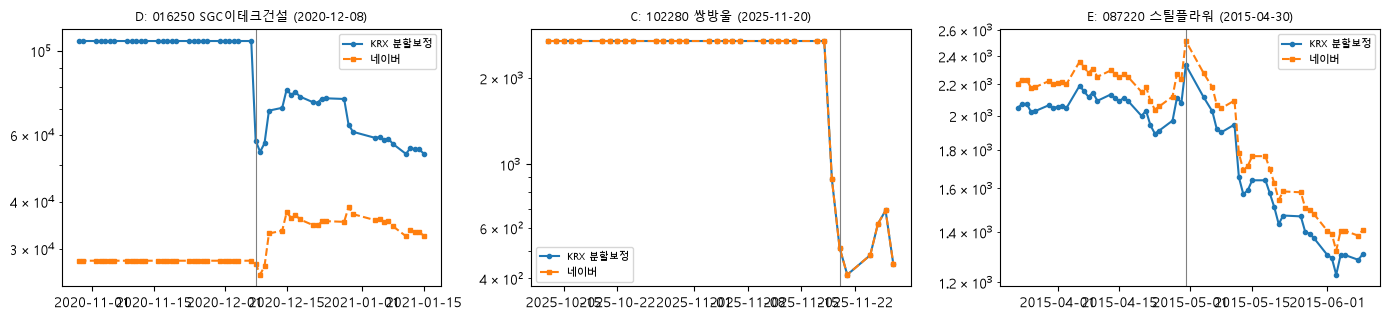

In [9]:
# 예시 그림: D·C·E 에서 한 건씩 골라, 큰 변동 날 앞뒤 40일의 KRX 분할보정 종가와 네이버 종가를 겹쳐 그린다.
def show(row, ax):
    n = external.load_naver(row.code)["close"]
    k = stock.loc[stock["code"] == row.code].set_index("date")["close_s"]
    lo, hi = row.date - pd.Timedelta(days=40), row.date + pd.Timedelta(days=40)
    k, n = k[(k.index >= lo) & (k.index <= hi)], n[(n.index >= lo) & (n.index <= hi)]
    ax.plot(k.index, k.values, "o-", label="KRX 분할보정", ms=3)
    ax.plot(n.index, n.values, "s--", label="네이버", ms=3)
    ax.axvline(row.date, color="gray", lw=0.8)
    ax.set_title(f"{row.kind[0]}: {row.code} {row['name']} ({row.date.date()})", fontsize=9)
    ax.set_yscale("log"); ax.legend(fontsize=7)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.3))
picks = pd.concat([jumps[jumps["kind"].str[0] == k].sample(1, random_state=3) for k in ("D", "C", "E")])
for (_, r), ax in zip(picks.iterrows(), axes):
    show(r, ax)
plt.tight_layout(); plt.show()

**읽는 법**: 왼쪽(D)은 두 선이 어긋난다(주식 수 변화 의심). 가운데(C)는 두 선이 겹친다(실제 큰 움직임). 오른쪽(E)은 남은 소수 중 하나다.

## 4. 배당 보정

- 배당을 주면 배당락일에 주가가 배당금만큼 내려간다. 현금이 주주에게 나갔기 때문이지 회사가 나빠져서가 아니다.
- 보정 계수 = 1 - 배당금 ÷ 배당락 전날 종가. 예) 종가 10,000원, 배당 500원 → 0.95. 배당락일 **이전** 가격에 곱한다.
- 자료는 두 곳이다.
  - **DART** (`dividends` 명령, 2015 사업연도부터): 연간 합계 배당금. 배당락일은 "연말 직전 거래일"로 **추정**한다.
  - **야후** (`yahoo_divs` 명령, 2011~2014): DART에 없는 앞 구간을 채운다. 야후는 실제 배당락일을 준다.
- `confidence`: `estimated`(2022 사업연도까지, 추정이 대체로 맞음) / `low`(2023 이후, 배당 기준일 제도가 바뀌어 날짜가 불확실).

DART 배당 이벤트: 12,013 건, 1716 종목 / 확인 목록: 478 건
야후 배당 이벤트(2011~2014): 3,776 건, 1116 종목
confidence 별 건수
confidence
estimated    8500
low          3513


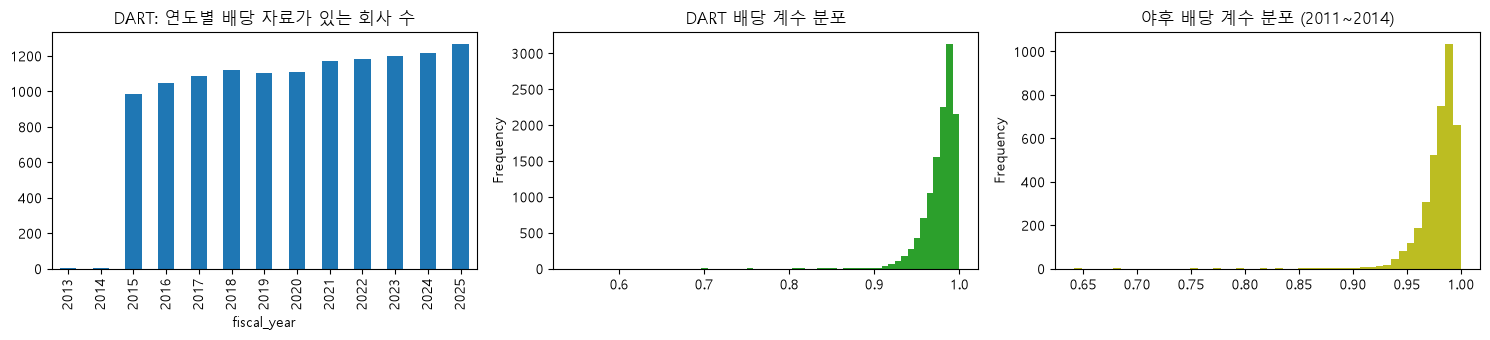

In [10]:
dps = pd.read_csv(paths.DART_CACHE / "dps_table.csv", dtype={"code": str})
divs = pd.read_csv(paths.DIV_EVENTS, dtype={"code": str}, parse_dates=["ex_date"])
div_review = pd.read_csv(paths.DIV_REVIEW, dtype={"code": str})
ydiv = pd.read_csv(paths.YAHOO_DIVS, dtype={"code": str}, parse_dates=["ex_date"])
print("DART 배당 이벤트:", f"{len(divs):,}", "건,", divs["code"].nunique(), "종목 / 확인 목록:", len(div_review), "건")
print("야후 배당 이벤트(2011~2014):", f"{len(ydiv):,}", "건,", ydiv["code"].nunique(), "종목")
print("confidence 별 건수"); print(divs["confidence"].value_counts().to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
dps[dps["dps"] > 0].groupby("fiscal_year")["code"].nunique().plot(kind="bar", ax=ax[0], color="tab:blue")
ax[0].set_title("DART: 연도별 배당 자료가 있는 회사 수")
divs["factor"].plot(kind="hist", bins=60, ax=ax[1], color="tab:green"); ax[1].set_title("DART 배당 계수 분포")
ydiv["factor"].plot(kind="hist", bins=50, ax=ax[2], color="tab:olive"); ax[2].set_title("야후 배당 계수 분포 (2011~2014)")
plt.tight_layout(); plt.show()

**읽는 법**
- DART 배당 자료는 **2015 사업연도부터**만 있다(2011~2014는 거의 0). 코드 오류가 아니라 DART 쪽 범위다. 그래서 그 앞은 야후로 채웠다.
- 계수가 0.97~0.99 근처에 몰려 있으면 정상이다(배당수익률 1~3%). 두 자료의 모양이 같으면 단위가 섞이지 않았다는 뜻이다.

In [11]:
# 삼성전자: DPS 는 2017년 42,500원 → 2018년 1,416원으로 크게 달라 보이지만 분할(50배) 때문이다.
# 계수는 "그때 실제 주가"로 나누므로 모든 해에 0.96~0.99 로 비슷해야 한다.
display(divs[divs["code"] == "005930"][["fiscal_year", "dps", "ex_date", "prev_close", "factor", "confidence"]])
display(ydiv[ydiv["code"] == "005930"][["ex_date", "dps", "prev_close", "factor"]])

# 확인 목록 이유별 건수: no_prev_close(가격 없음) / non_december_fy(12월 결산 아님) / implausible_factor(말이 안 되는 값)
r = div_review.copy()
r["type"] = r["reason"].str.replace(r"\(.*\)", "", regex=True)
print(r["type"].value_counts().to_string())

,fiscal_year,dps,ex_date,prev_close,factor,confidence
2023,2015,"21,000.0000",2015-12-29,"1,266,000.0000",0.9834,estimated
2024,2016,"28,500.0000",2016-12-28,"1,799,000.0000",0.9842,estimated
2025,2017,"42,500.0000",2017-12-27,"2,410,000.0000",0.9824,estimated
2026,2018,"1,416.0000",2018-12-27,"38,350.0000",0.9631,estimated
2027,2019,"1,416.0000",2019-12-27,"55,400.0000",0.9744,estimated
2028,2020,"2,994.0000",2020-12-29,"78,700.0000",0.9620,estimated
2029,2021,"1,444.0000",2021-12-29,"80,300.0000",0.9820,estimated
2030,2022,"1,444.0000",2022-12-28,"58,100.0000",0.9751,estimated
2031,2023,"1,444.0000",2023-12-27,"76,600.0000",0.9811,low
2032,2024,"1,446.0000",2024-12-27,"53,600.0000",0.9730,low


,ex_date,dps,prev_close,factor
887,2011-12-28,100.0000,"21,460.0000",0.9953
888,2012-06-28,10.0000,"23,340.0000",0.9996
889,2012-12-27,150.0000,"29,400.0000",0.9949
890,2013-06-27,10.0000,"25,220.0000",0.9996
891,2013-12-27,276.0000,"28,160.0000",0.9902
892,2014-06-27,10.0000,"26,500.0000",0.9996
893,2014-12-29,390.0000,"27,040.0000",0.9856


type
non_december_fy       283
no_prev_close         190
implausible_factor      5


**배당 보정의 한계 (숨기지 않는다)**
- DART는 **연간 합계** 배당이다. 분기배당 회사도 연말 한 번에 빠진 것으로 계산한다(연 단위 영향은 작지만 일별 정밀도는 낮다).
- `low`(2023 이후)는 날짜가 불확실하다. `adjust --exclude-low` 로 뺀 버전을 따로 만들어 결과가 달라지는지 비교할 수 있다.
- 배당이 전일종가의 10%를 넘는데 배당락일에 실제 가격이 이론 하락의 1/3도 안 떨어진 것은 단위·날짜 오류로 보고 뺀다(`drop_unsupported_big_dividends`).
- 2026 사업연도 배당은 아직 DART에 없다. 2011~2014 야후 배당은 상장폐지 종목에 없다.

## 5. 주주배정 유상증자(권리락) 보정

- **유상증자 중 주주배정**은 기존 주주에게 "싼 값에 새 주식을 살 권리"를 준다. 권리락일에 주가는 그 권리만큼 내려간다.
- 이론 권리락 가격 = (전일종가 x 기존주식수 + 발행가 x 신주수) ÷ (기존주식수 + 신주수). 과거 가격에 `이론가 ÷ 전일종가` 를 곱한다.
- DART 공시에는 권리락 날짜도 발행가도 직접 없다. 발행가는 `조달금액 ÷ 신주수`, 날짜는 KRX 가격에서 이론 하락과 가장 비슷한 날로 찾는다(`rights.find_ex_date`).
- 우연히 맞는 날을 거르려고 **상장주식수가 신주만큼(80~120%) 늘었는지**를 두 번째 증거로 쓴다.
  - 가짜 실험: 같은 공시를 1년 전 날짜로 옮겨 같은 방법을 돌리면 두 증거를 모두 만족한 것은 503건 중 3건(약 0.6%)뿐이었다. 그래서 확정 이벤트 중 우연히 맞은 것은 많아야 2% 안팎이다. (이 실험은 무거워서 여기서는 결과만 적는다.)
- `confirmed`(두 증거 모두 맞음)만 보정에 쓴다. `review`·`unconfirmed` 는 파일에만 남긴다.
- 기준가 보정(6절)과 겹치지 않도록, 권리락일 3일 안에 기준가 이벤트가 있으면 유상증자 쪽은 빼고 기준가 쪽 하나만 쓴다.

confidence
unconfirmed    368
confirmed      143
review          55
확정 이벤트 연도별: {2015: 12, 2016: 12, 2017: 15, 2018: 15, 2019: 8, 2020: 15, 2021: 11, 2022: 10, 2023: 10, 2024: 10, 2025: 17, 2026: 8}
최종 표에서 rights_factor 가 1이 아닌 종목 수: 134


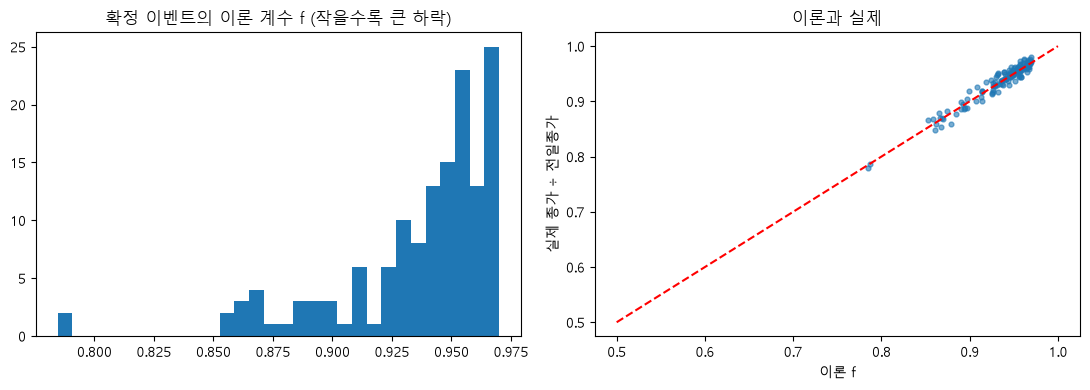

In [12]:
rights_ev = pd.read_csv(paths.RIGHTS_EVENTS, dtype={"code": str}, parse_dates=["ex_date"])
print(rights_ev["confidence"].value_counts().to_string())
conf = rights_ev[rights_ev["confidence"] == "confirmed"]
print("확정 이벤트 연도별:", conf["ex_date"].dt.year.value_counts().sort_index().to_dict())
print("최종 표에서 rights_factor 가 1이 아닌 종목 수:", adj.loc[adj["rights_factor"] != 1, "code"].nunique())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(conf["factor"], bins=30); ax[0].set_title("확정 이벤트의 이론 계수 f (작을수록 큰 하락)")
ax[1].scatter(conf["factor"], conf["obs_ratio"], s=12, alpha=.6); ax[1].plot([.5, 1], [.5, 1], "r--")
ax[1].set_xlabel("이론 f"); ax[1].set_ylabel("실제 종가 ÷ 전일종가"); ax[1].set_title("이론과 실제")
plt.tight_layout(); plt.show()

          보정 전     보정 후
count 143.0000 143.0000
mean   -0.0622   0.0015
std     0.0356   0.0087
min    -0.2212  -0.0222
25%    -0.0713  -0.0029
50%    -0.0512   0.0012
75%    -0.0384   0.0065
max    -0.0194   0.0217
보정 후 등락 절댓값이 3% 이내: 100.0%


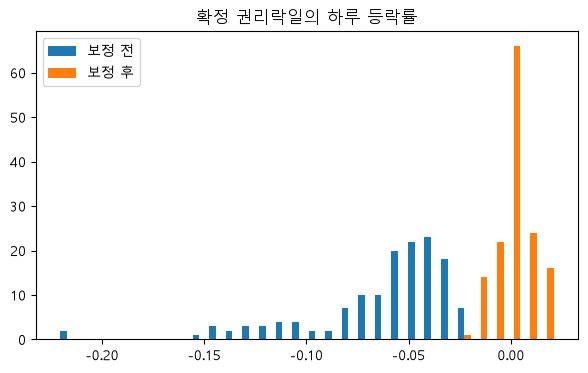

In [13]:
# 확정 권리락일의 하루 등락: 원래 종가(보정 전) vs 최종 adj_close(보정 후). 보정이 맞으면 0 근처로 모인다.
sub = adj[adj["code"].isin(conf["code"])].copy()
sub["r_before"] = sub.groupby("code")["close"].pct_change()
sub["r_after"] = sub.groupby("code")["adj_close"].pct_change()
ba = conf[["code", "ex_date"]].merge(sub.rename(columns={"date": "ex_date"})[["code", "ex_date", "r_before", "r_after", "rights_factor"]],
                                      on=["code", "ex_date"], how="inner")
print(ba[["r_before", "r_after"]].rename(columns={"r_before": "보정 전", "r_after": "보정 후"}).describe().round(4).to_string())
print("보정 후 등락 절댓값이 3% 이내:", f"{(ba['r_after'].abs() <= .03).mean():.1%}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist([ba["r_before"], ba["r_after"]], bins=30, label=["보정 전", "보정 후"]); ax.legend()
ax.set_title("확정 권리락일의 하루 등락률"); plt.show()

**읽는 법과 정정**
- 보정 후 분포가 0 근처로 모이면 가짜 하락이 사라진 것이다. 같은 날 배당·기준가 보정과 겹친 건은 조금 다를 수 있다.
- **정정**: 예전 06번 노트북은 "네이버·야후는 유상증자를 보정하지 않는다"고 썼다. 이것은 **DART로 추정한 권리락일**에서만 맞는 말이었다. KRX 기준가로 진짜 조정일을 보면 네이버는 기준가가 크게 바뀐 날의 90% 이상을 보정했다(02번 노트북 3절). 그래서 지금은 기준가 이벤트(6절)를 주 보정으로 쓰고, 유상증자는 기준가 이벤트와 겹치지 않는 확정 건만 보탠다.

## 6. 기준가 보정 (`base_factor`)

- **기준가**: 거래소가 그날의 시작 가격으로 정해 주는 값. 평소에는 전날 종가와 같고, 권리락·감자·분할합병 같은 일이 있으면 달라진다.
- 기준가 ÷ 전일종가 가 **0.95 미만 또는 1.01 초과**인 날(분할일 제외)을 "거래소가 가격을 바꿔 준 날"로 보고, 그 비율을 과거 가격에 곱한다(`base.py`).
- 같은 일을 두 번 보정하지 않도록: 기준가 이벤트 3일 안의 유상증자, 같은 날의 배당은 뺀다.
- 기준가 이벤트에서 **거래량은 보정하지 않는다** (유동성은 거래대금 `value` 로 본다).

In [14]:
base_ev = pd.read_csv(paths.BASE_EVENTS, dtype={"code": str}, parse_dates=["ex_date"])
print("기준가 이벤트:", len(base_ev), "건,", base_ev["code"].nunique(), "종목")
print(pd.cut(base_ev["factor"], [0, .5, .8, .9, .95, 1.01, 1.2, 3, 200]).value_counts().sort_index().to_string())

# 반영 전후 비교: 반영 전 가격 = 반영 후 가격 ÷ base_factor (계수만 되돌리면 된다)
stock["adj_close"] = adj.loc[stock.index, "adj_close"]
stock["no_base"] = stock["adj_close"] / adj.loc[stock.index, "base_factor"]
g = stock.groupby("code", sort=False)
stock["ret_adj"] = g["adj_close"].pct_change()
stock["ret_nobase"] = g["no_base"].pct_change()
print()
print("하루 31% 초과 (코스피·코스닥)")
print("  원래 종가                 :", f"{(stock['ret_raw'].abs() > LIMIT).sum():,}")
print("  분할 보정                 :", f"{(stock['ret_s'].abs() > LIMIT).sum():,}")
print("  분할+배당+유상 (기준가 전) :", f"{(stock['ret_nobase'].abs() > LIMIT).sum():,}")
print("  최종 adj_close            :", f"{(stock['ret_adj'].abs() > LIMIT).sum():,}")
print("보정 가격이 비었거나 0 이하인 줄:", int((adj["adj_close"].isna() | (adj["adj_close"] <= 0)).sum()))

기준가 이벤트: 1730 건, 1076 종목
factor
(0.0, 0.5]       60
(0.5, 0.8]      179
(0.8, 0.9]      440
(0.9, 0.95]     529
(0.95, 1.01]      0
(1.01, 1.2]     191
(1.2, 3.0]      225
(3.0, 200.0]    106



하루 31% 초과 (코스피·코스닥)
  원래 종가                 : 3,139
  분할 보정                 : 1,502
  분할+배당+유상 (기준가 전) : 1,508
  최종 adj_close            : 1,103


보정 가격이 비었거나 0 이하인 줄: 0


## 7. 최종 표 한눈에 보기 — 삼성전자

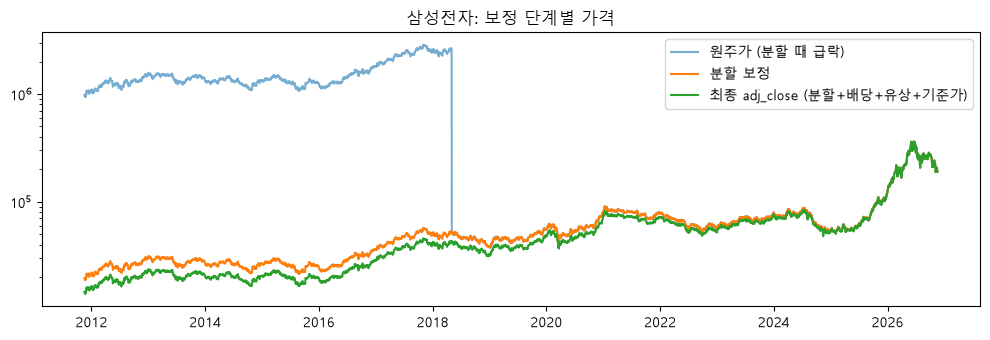

In [15]:
x = adj[adj["code"] == "005930"].set_index("date")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(x.index, x["close"], label="원주가 (분할 때 급락)", alpha=0.6)
ax.plot(x.index, x["close_s"], label="분할 보정")
ax.plot(x.index, x["adj_close"], label="최종 adj_close (분할+배당+유상+기준가)")
ax.set_yscale("log"); ax.set_title("삼성전자: 보정 단계별 가격"); ax.legend()
plt.tight_layout(); plt.show()

**읽는 법**: 원주가는 2018년에 뚝 떨어지고, 분할 보정은 이어지며, 최종 가격은 과거로 갈수록 더 낮게 시작해 같은 곳에서 끝난다. 그동안 받은 배당만큼 과거 가격에서 미리 빼 주었기 때문이다.

## 정리

- **끝난 것**: 분할(1,840건 안팎), 배당(DART 2015~ + 야후 2011~2014), 확정 유상증자, 기준가 보정(1,730건 안팎). 하루 31% 초과 건수가 단계마다 줄어드는 것을 위에서 확인했다.
- **남은 것**
  1. 최종 보정 후에도 남은 하루 31% 초과 약 1,100건(B·C처럼 네이버에도 있는 실제 움직임이 많다)과 확인 목록의 D·E 건, 분할일 큰 변동 중 원인 미확인 건
  2. 날짜가 불확실한 배당(`low`) — `--exclude-low` 버전과 비교해서 결정
  3. 네이버와 맞지 않는 종목 → 03번 노트북의 `krx_quality_flags.csv` 의심 표시로 관리
  4. 기준가 이벤트에서 거래량은 보정하지 않음
- **다음**: 02번 노트북에서 네이버·야후와 비교해 이 보정이 외부 자료와 얼마나 맞는지 본다.